# Exercice 3 — Classification des fleurs Iris 🌸

Objectif : prédire l'espèce d'une fleur (setosa, versicolor, virginica) à partir de quatre mesures :
longueur et largeur des sépales, longueur et largeur des pétales. 150 fleurs, 3 classes.

## 1. Préparation des données

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)
print("Colonnes :", iris.feature_names)
print("Classes  :", [str(c) for c in iris.target_names])

Dimensions : torch.Size([120, 4]) torch.Size([120])
Colonnes : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes  : ['setosa', 'versicolor', 'virginica']


### Questions

**Que représentent les quatre colonnes de `X_train` ?**
Les quatre mesures de chaque fleur, en cm : longueur du sépale, largeur du sépale, longueur du pétale, largeur du pétale. Après le `StandardScaler`, elles sont centrées-réduites : moyenne 0 et écart-type 1 sur l'entraînement.

**Pourquoi utilise-t-on `torch.long` pour les étiquettes ?**
`nn.CrossEntropyLoss` attend des **indices de classe entiers** (0, 1 ou 2) de type `int64`. Elle les utilise pour sélectionner le logit de la bonne classe. Ce ne sont pas des valeurs continues à approcher : un `float` provoquerait une erreur, ou serait interprété comme des probabilités.

**Pourquoi ne faut-il pas ajuster le `StandardScaler` sur les données de test ?**
Le test doit simuler des données **jamais vues**. Calculer la moyenne et l'écart-type avec le test ferait « fuir » de l'information du test vers la préparation (*data leakage*), et l'évaluation serait trop optimiste. On ajuste (`fit`) sur l'entraînement, puis on applique la même transformation (`transform`) au test et aux nouvelles fleurs.

## 2. Construire le réseau

4 entrées → couche cachée de 16 neurones (ReLU) → 3 sorties (une par espèce). **Pas de Softmax** : `CrossEntropyLoss` attend les logits.

In [2]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=3, bias=True)
)


## 3. Entraîner le modèle (toutes les données d'entraînement à chaque itération)

In [3]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    optimizer.zero_grad()                 # remettre les gradients à zéro
    logits = model(X_train)               # calculer les scores prédits
    loss = criterion(logits, y_train)     # calculer la perte
    loss.backward()                       # calculer les gradients
    optimizer.step()                      # mettre à jour les paramètres

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525


Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463


Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


## 4. Évaluer le classifieur

In [4]:
model.eval()

with torch.no_grad():
    logits = model(X_test)
    predictions = logits.argmax(dim=1)                       # classe au score maximal
    accuracy = (predictions == y_test).float().mean()        # proportion correcte

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


## 5. Autres questions
### Courbe de perte

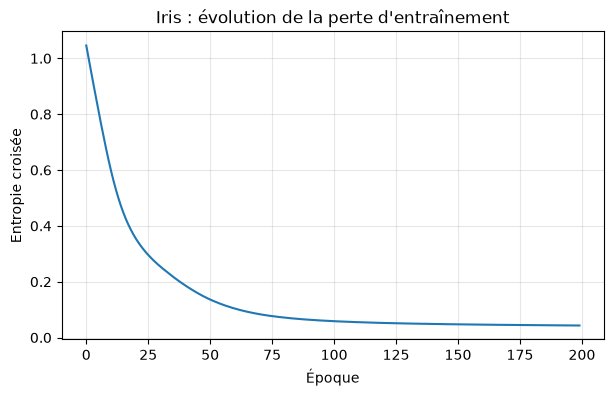

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("Entropie croisée")
plt.title("Iris : évolution de la perte d'entraînement")
plt.grid(True, alpha=0.3)
plt.show()

### Matrice de confusion

tensor([[10,  0,  0],
        [ 0, 10,  0],
        [ 0,  0, 10]])


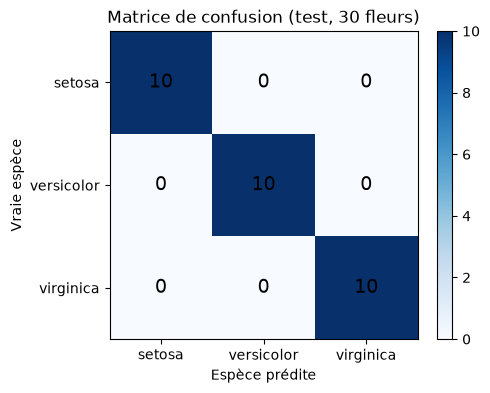

In [6]:
from torchmetrics.classification import MulticlassConfusionMatrix

matrice = MulticlassConfusionMatrix(num_classes=3)(predictions, y_test)
print(matrice)

plt.figure(figsize=(5, 4))
plt.imshow(matrice, cmap="Blues")
for i in range(3):
    for j in range(3):
        plt.text(j, i, int(matrice[i, j]), ha="center", va="center", fontsize=14)
plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)
plt.xlabel("Espèce prédite")
plt.ylabel("Vraie espèce")
plt.title("Matrice de confusion (test, 30 fleurs)")
plt.colorbar()
plt.show()

### Comparaison avec un modèle sans couche cachée : `nn.Linear(4, 3)`

Les deux modèles sont entraînés dans les mêmes conditions (Adam lr=0.01, 200 époques). Comme le test ne compte
que 30 fleurs (une erreur = 3.3 points), on répète l'expérience sur 10 graines différentes.

In [7]:
def entrainer(construire, graine):
    torch.manual_seed(graine)
    m = construire()
    opt = torch.optim.Adam(m.parameters(), lr=0.01)
    m.train()
    for _ in range(200):
        opt.zero_grad()
        perte = criterion(m(X_train), y_train)
        perte.backward()
        opt.step()
    m.eval()
    with torch.no_grad():
        acc = (m(X_test).argmax(1) == y_test).float().mean().item()
    return perte.item(), acc, sum(p.numel() for p in m.parameters())


modeles = {
    "Sans couche cachée : Linear(4, 3)": lambda: nn.Linear(4, 3),
    "Avec couche cachée : 4 -> 16 -> 3": lambda: nn.Sequential(nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 3)),
}
for nom, construire in modeles.items():
    res = [entrainer(construire, g) for g in range(10)]
    pertes = torch.tensor([r[0] for r in res])
    accs = torch.tensor([r[1] for r in res])
    print(f"{nom:<36} | {res[0][2]:3d} paramètres | perte train {pertes.mean():.3f} "
          f"| accuracy test {accs.mean():.1%} (min {accs.min():.1%}, max {accs.max():.1%})")

Sans couche cachée : Linear(4, 3)    |  15 paramètres | perte train 0.252 | accuracy test 90.7% (min 83.3%, max 93.3%)


Avec couche cachée : 4 -> 16 -> 3    | 131 paramètres | perte train 0.042 | accuracy test 97.7% (min 96.7%, max 100.0%)


**Interprétation.** `Linear(4, 3)` est une **régression logistique multinomiale** : ses frontières de décision sont des
droites (hyperplans). Setosa est parfaitement séparable des deux autres espèces, mais la frontière versicolor/virginica
est plus délicate. Avec le même budget (200 époques, lr = 0.01), le modèle linéaire reste à une perte d'entraînement
d'environ 0.25 et environ 91 % en test. Le réseau avec couche cachée (non linéaire grâce à la ReLU, 131 paramètres
contre 15) descend à une perte d'environ 0.04 et environ 98 % en test, de façon plus stable d'une graine à l'autre.
La couche cachée apporte donc à la fois de la capacité (frontières non linéaires) et une convergence plus rapide.
Iris étant presque linéairement séparable, un modèle linéaire entraîné plus longtemps se rapprocherait toutefois du réseau.

### Prédire l'espèce d'une nouvelle fleur [5.1, 3.5, 1.4, 0.2]

In [8]:
nouvelle_fleur = [[5.1, 3.5, 1.4, 0.2]]
nouvelle_fleur_norm = torch.tensor(scaler.transform(nouvelle_fleur), dtype=torch.float32)  # même scaler

with torch.no_grad():
    logits = model(nouvelle_fleur_norm)
    probas = torch.softmax(logits, dim=1)[0]      # Softmax seulement pour lire des probabilités
    classe = probas.argmax().item()

print("Mesures normalisées :", nouvelle_fleur_norm)
for nom, p in zip(iris.target_names, probas):
    print(f"  {nom:<11} : {p.item():.2%}")
print("Espèce prédite :", iris.target_names[classe])

Mesures normalisées : tensor([[-0.8857,  1.0112, -1.3457, -1.3233]])
  setosa      : 99.99%
  versicolor  : 0.01%
  virginica   : 0.00%
Espèce prédite : setosa


Petits pétales (1.4 × 0.2 cm) → la fleur est prédite **setosa**, avec une très forte probabilité.
C'est d'ailleurs exactement la première fleur du jeu de données Iris, qui est une setosa.